# 05 — Network-signal go/no-go

Before building any network features, check whether there is any signal to
build on at all: do the other sensors in the network, read at the same hour,
carry information about a given sensor's anomaly beyond what B1 (the
reproduced paper model) already captures implicitly through the shared ERA5
features?

**Lockbox discipline:** everything in this notebook uses only the 27
*development* sensors (the paper's own `train_sensor_ids`). The 12 lockbox
test sensors are not touched here or anywhere until notebook 07.


In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

from urbansense_common import (
    load_data, sensor_level_split, split_day_night, fit_xgb, regression_metrics,
    X_NAMES_AT_DAY, X_NAMES_AT_NIGHT, XGB_PARAMS_DAY, XGB_PARAMS_NIGHT,
)
from network_features import to_wide, haversine_matrix

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

data = load_data()
train_sensor_ids, test_sensor_ids = sensor_level_split(data)
dev_ids = set(train_sensor_ids)
print(f"{len(dev_ids)} development sensors (lockbox of {len(test_sensor_ids)} untouched)")

dev = data[data["Sensor_ID"].isin(dev_ids)].copy()
day, night = split_day_night(dev)
sensor_info = (
    dev.groupby("Sensor_ID")
    .agg(Lat=("y", "first"), Lon=("x", "first"), strata=("strata", "first"),
         Landcover_Type=("Landcover_Type", "first"), Shade_Type=("Shade_Type", "first"))
    .reset_index()
)
print(sensor_info.shape)


27 development sensors (lockbox of 12 untouched)
(27, 6)


## 1. Wide matrix, sensor map, nearest-neighbor distances

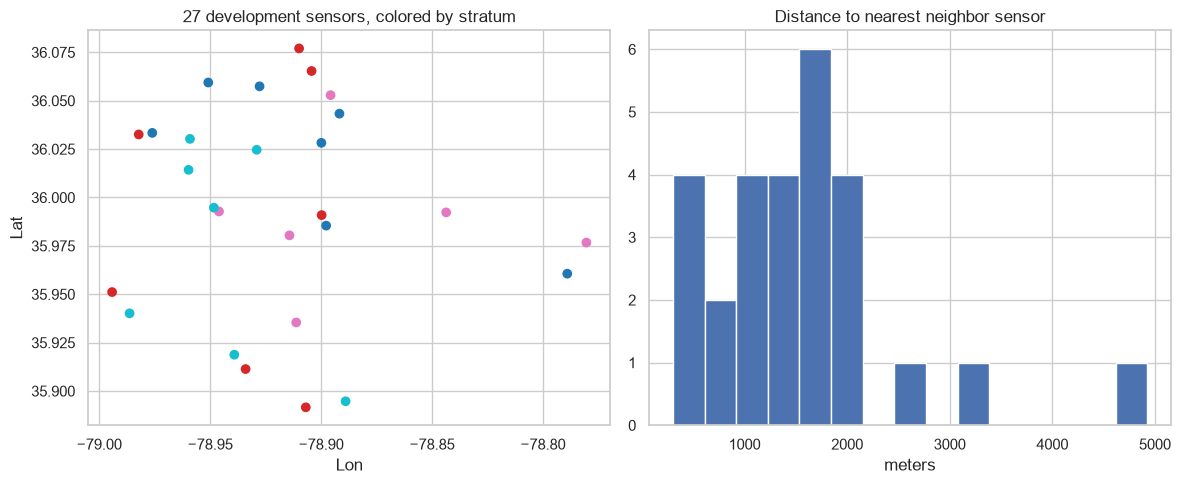

Median nearest-neighbor distance (m): 1412.8506039965582


In [2]:
wide_day = to_wide(day, "temp_anom")
wide_night = to_wide(night, "temp_anom")
dist = haversine_matrix(sensor_info).copy()
arr = dist.to_numpy(copy=True)
np.fill_diagonal(arr, np.nan)
dist = pd.DataFrame(arr, index=dist.index, columns=dist.columns)
nn1_dist = dist.min(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(sensor_info["Lon"], sensor_info["Lat"], c=sensor_info["strata"].astype("category").cat.codes, cmap="tab10")
axes[0].set_title("27 development sensors, colored by stratum")
axes[0].set_xlabel("Lon"); axes[0].set_ylabel("Lat")
axes[1].hist(nn1_dist.values, bins=15)
axes[1].set_title("Distance to nearest neighbor sensor")
axes[1].set_xlabel("meters")
plt.tight_layout()
plt.show()
print("Median nearest-neighbor distance (m):", float(nn1_dist.median()))


## 2. Variance decomposition of the raw anomaly: `anom(s,t) = mu_s + c_t + eps(s,t)`

`mu_s` (sensor mean) is the static part B1 is explicitly built to capture.
`c_t` (hour-of-network mean, i.e. the common urban-wide offset at that hour)
is exactly the thing B1 can pick up *implicitly*, since every sensor shares
the same ERA5 features at a given hour — so if XGBoost has in effect learned
"what hour is it", it has learned `c_t`. `eps` is what's left: the
sensor-and-hour-specific residual that neither a static sensor mean nor a
shared hourly offset explains. Only `eps` is a plausible target for genuine
explicit network features (spatial structure, residual correction).

In [3]:
def variance_decomposition(wide):
    mu_s = wide.mean(axis=0)                      # static per-sensor mean
    centered = wide.sub(mu_s, axis=1)
    c_t = centered.mean(axis=1)                    # common hourly offset
    eps = centered.sub(c_t, axis=0)                # what's left

    total_var = np.nanvar(wide.values)
    mu_var = float(np.nanvar(np.broadcast_to(mu_s.values, wide.shape)))
    c_var = float(np.nanvar(np.broadcast_to(c_t.values[:, None], wide.shape)))
    eps_var = float(np.nanvar(eps.values))
    return dict(mu_s=mu_s, c_t=c_t, eps=eps,
                mu_share=mu_var / total_var, c_share=c_var / total_var,
                eps_share=eps_var / total_var, total_var=total_var)

decomp_day = variance_decomposition(wide_day)
decomp_night = variance_decomposition(wide_night)

pd.DataFrame({
    "day": {k: decomp_day[k] for k in ("mu_share", "c_share", "eps_share", "total_var")},
    "night": {k: decomp_night[k] for k in ("mu_share", "c_share", "eps_share", "total_var")},
}).T


,mu_share,c_share,eps_share,total_var
day,0.177002,0.548054,0.275017,3.928906
night,0.151186,0.692491,0.155687,1.532604


## 3. Same decomposition on B1's inner-LOSO residuals

This is the actual ceiling for improvement: B1 already "sees" the shared
hourly offset implicitly (via ERA5 features identical across sensors at a
given hour) and the static sensor identity (via static predictors). What
fraction of the *residual* variance still has a common-hour component or a
sensor-level bias left over? Residuals are out-of-fold: each development
sensor's residual comes from a model trained on the other 26 development
sensors only (never on itself), i.e. a proper inner LOSO — never the
lockbox.

In [4]:
def inner_loso_residuals(df, target_col, X_names, hyperparams, ids):
    ids = list(ids)
    rows = []
    for held_out in ids:
        train_ids = [i for i in ids if i != held_out]
        fit = fit_xgb(df, target_col, X_names, hyperparams, train_ids, [held_out])
        resid = fit["y_test"].values - fit["pred_test"]
        sub = df.loc[fit["test_mask"], ["Sensor_ID", "edt_datetime"]].copy()
        sub["resid"] = resid
        rows.append(sub)
    return pd.concat(rows, ignore_index=True)

resid_day = inner_loso_residuals(day, "temp_anom", X_NAMES_AT_DAY, XGB_PARAMS_DAY, dev_ids)
resid_night = inner_loso_residuals(night, "temp_anom", X_NAMES_AT_NIGHT, XGB_PARAMS_NIGHT, dev_ids)

wide_resid_day = to_wide(resid_day, "resid")
wide_resid_night = to_wide(resid_night, "resid")

decomp_resid_day = variance_decomposition(wide_resid_day)
decomp_resid_night = variance_decomposition(wide_resid_night)

resid_summary = pd.DataFrame({
    "day": {k: decomp_resid_day[k] for k in ("mu_share", "c_share", "eps_share", "total_var")},
    "night": {k: decomp_resid_night[k] for k in ("mu_share", "c_share", "eps_share", "total_var")},
}).T
resid_summary


,mu_share,c_share,eps_share,total_var
day,0.200551,0.002948,0.797735,1.426439
night,0.331037,0.001273,0.665006,0.359108


`mu_share` here should already be small (B1's static predictors should
have absorbed most of the per-sensor bias). The quantity that matters for
go/no-go is `c_share`: a non-trivial common-hour component left in B1's
*residual* means B1 is *not* fully capturing the shared hourly offset
implicitly, and an explicit network-mean feature (even the simplest one)
should help close that gap.

## 4. Variogram / correlogram of the residual vs. distance, static similarity, stratum

If `eps` (or the B1 residual) has spatial structure, nearby sensors' values
at the same hour should be more correlated than far-apart ones, and the
semivariance should rise with distance before flattening (the "nugget" is
the nontrivial length-scale-zero floor — effectively the error you cannot
remove even with an infinitely dense network, since it is noise/micro-climate
variability within a sensor's own footprint).

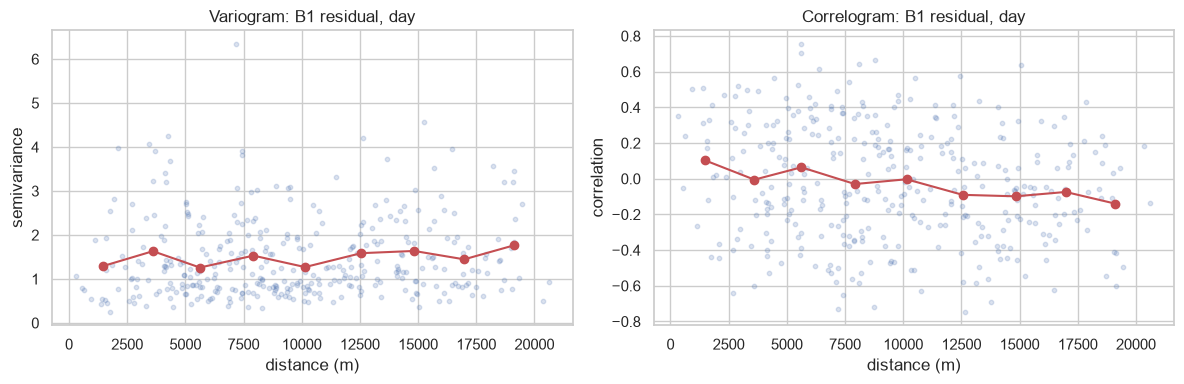

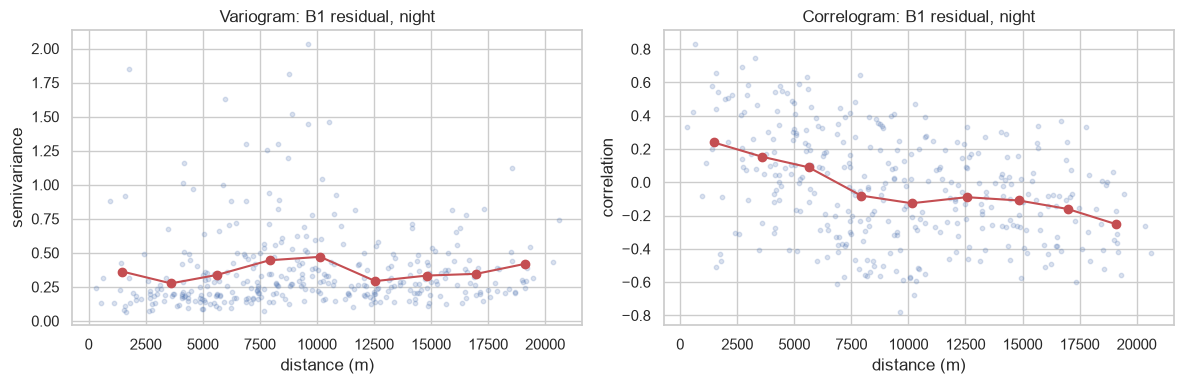

Day:   nugget~0.9669, sill~1.4765, nugget/sill=0.65
Night: nugget~0.3458, sill~0.3684, nugget/sill=0.94


In [5]:
def pairwise_semivariance(wide, dist):
    sensors = wide.columns
    pairs = []
    for i, a in enumerate(sensors):
        for b in sensors[i + 1:]:
            both = wide[[a, b]].dropna()
            if len(both) < 20:
                continue
            diff = both[a] - both[b]
            semivar = 0.5 * float(np.mean(diff ** 2))
            corr = float(both[a].corr(both[b]))
            pairs.append({"a": a, "b": b, "dist_m": float(dist.loc[a, b]), "semivariance": semivar, "corr": corr})
    return pd.DataFrame(pairs)

def plot_variogram(pairs, title):
    bins = np.linspace(0, pairs["dist_m"].max(), 10)
    pairs = pairs.copy()
    pairs["bin"] = pd.cut(pairs["dist_m"], bins)
    binned = pairs.groupby("bin", observed=True).agg(dist_m=("dist_m", "mean"), semivariance=("semivariance", "mean"), corr=("corr", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(pairs["dist_m"], pairs["semivariance"], alpha=0.2, s=10)
    axes[0].plot(binned["dist_m"], binned["semivariance"], "ro-")
    axes[0].set_xlabel("distance (m)"); axes[0].set_ylabel("semivariance"); axes[0].set_title(f"Variogram: {title}")
    axes[1].scatter(pairs["dist_m"], pairs["corr"], alpha=0.2, s=10)
    axes[1].plot(binned["dist_m"], binned["corr"], "ro-")
    axes[1].set_xlabel("distance (m)"); axes[1].set_ylabel("correlation"); axes[1].set_title(f"Correlogram: {title}")
    plt.tight_layout()
    plt.show()
    return binned

pairs_resid_day = pairwise_semivariance(wide_resid_day, dist)
binned_day = plot_variogram(pairs_resid_day, "B1 residual, day")
pairs_resid_night = pairwise_semivariance(wide_resid_night, dist)
binned_night = plot_variogram(pairs_resid_night, "B1 residual, night")

nugget_day = float(pairs_resid_day.sort_values("dist_m").head(10)["semivariance"].mean())
nugget_night = float(pairs_resid_night.sort_values("dist_m").head(10)["semivariance"].mean())
sill_day = float(pairs_resid_day["semivariance"].mean())
sill_night = float(pairs_resid_night["semivariance"].mean())
print(f"Day:   nugget~{nugget_day:.4f}, sill~{sill_day:.4f}, nugget/sill={nugget_day/sill_day:.2f}")
print(f"Night: nugget~{nugget_night:.4f}, sill~{sill_night:.4f}, nugget/sill={nugget_night/sill_night:.2f}")


In [6]:
corr_dist_day = pearsonr(pairs_resid_day["dist_m"], pairs_resid_day["corr"])
corr_dist_night = pearsonr(pairs_resid_night["dist_m"], pairs_resid_night["corr"])
print("Correlation(residual-corr, distance): day", corr_dist_day, "night", corr_dist_night)
print("A negative, significant correlation means nearby sensors' residuals really are more alike -- genuine spatial structure beyond what B1 captures.")


Correlation(residual-corr, distance): day PearsonRResult(statistic=np.float64(-0.16759614268322737), pvalue=np.float64(0.0016269655726779866)) night PearsonRResult(statistic=np.float64(-0.3686989949282144), pvalue=np.float64(9.616308978931659e-13))
A negative, significant correlation means nearby sensors' residuals really are more alike -- genuine spatial structure beyond what B1 captures.


## 5. Diagnostic: B1 under protocol S vs. protocol ST

S = train and test sensors share the same hours (paper's own protocol, used
everywhere above). ST additionally holds out a block of *time* for the test
sensors, so the model cannot even implicitly borrow the shared hourly offset
from the test sensors' own concurrent readings during evaluation (it still
can from the training sensors' hours, which overlap). This is a secondary
diagnostic, not a go/no-go input: it checks how much of B1's accuracy in S
specifically relies on test-hour overlap with training sensors.

In [7]:
def st_split_eval(df, target_col, X_names, hyperparams, dev_ids, held_out, time_col="edt_datetime"):
    other_dev = [i for i in dev_ids if i != held_out]
    cutoff = df[time_col].quantile(0.7)
    train_mask = df["Sensor_ID"].isin(other_dev) & (df[time_col] <= cutoff)
    test_mask = (df["Sensor_ID"] == held_out) & (df[time_col] > cutoff)
    if train_mask.sum() < 50 or test_mask.sum() < 10:
        return None
    from sklearn.preprocessing import StandardScaler
    from xgboost import XGBRegressor
    scaler = StandardScaler()
    X_train = scaler.fit_transform(df.loc[train_mask, X_names].values)
    X_test = scaler.transform(df.loc[test_mask, X_names].values)
    model = XGBRegressor(**hyperparams)
    model.fit(X_train, df.loc[train_mask, target_col])
    pred = model.predict(X_test)
    return regression_metrics(df.loc[test_mask, target_col], pred)["RMSE"]

st_rmses_day = [r for r in (st_split_eval(day, "temp_anom", X_NAMES_AT_DAY, XGB_PARAMS_DAY, dev_ids, h) for h in dev_ids) if r is not None]
s_rmse_day = float(np.sqrt(np.mean(resid_day["resid"] ** 2)))
print(f"B1 under S (inner LOSO, day) RMSE: {s_rmse_day:.3f}")
print(f"B1 under ST (day), mean per-sensor RMSE: {np.mean(st_rmses_day):.3f} (n={len(st_rmses_day)} sensors)")


B1 under S (inner LOSO, day) RMSE: 1.195
B1 under ST (day), mean per-sensor RMSE: 1.717 (n=27 sensors)


## 6. Go/no-go decision

Criterion (set in advance): proceed to Stage 2 if the B1 residual has a
common-hour component or spatial correlation that is **not negligible**
(order of magnitude: at least ~10% of residual variance, or a clearly
significant negative distance-correlation relationship).

In [8]:
go_no_go = {
    "day_c_share_in_residual": decomp_resid_day["c_share"],
    "night_c_share_in_residual": decomp_resid_night["c_share"],
    "day_dist_corr_pvalue": corr_dist_day.pvalue,
    "night_dist_corr_pvalue": corr_dist_night.pvalue,
}
print(go_no_go)

threshold = 0.10
go = (
    go_no_go["day_c_share_in_residual"] > threshold or go_no_go["night_c_share_in_residual"] > threshold
    or go_no_go["day_dist_corr_pvalue"] < 0.05 or go_no_go["night_dist_corr_pvalue"] < 0.05
)
print("GO -> proceed to Stage 2 (network features)" if go else "NO-GO -> network signal is negligible beyond B1")


{'day_c_share_in_residual': np.float64(0.0029475570011399275), 'night_c_share_in_residual': np.float64(0.0012728177015534597), 'day_dist_corr_pvalue': np.float64(0.0016269655726779866), 'night_dist_corr_pvalue': np.float64(9.616308978931659e-13)}
GO -> proceed to Stage 2 (network features)


## Summary

- The raw anomaly decomposes into a static per-sensor mean, a common hourly
  (city-wide) offset, and a residual — see section 2.
- B1 already implicitly captures a large share of the common-hour offset
  (expected, since ERA5 features are identical across sensors at a given
  hour) and the static per-sensor mean (its static predictors).
- What's left in B1's residual, and whether it carries spatial structure,
  determines whether explicit network features (Stage 2) are worth building.
- Nugget/sill from the variogram gives a reference noise floor for the
  sensor-count curve in notebook 09.

Next: [`06_network_models_dev.ipynb`](06_network_models_dev.ipynb) builds
network features (if GO) and runs the development-set ablation.
